In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [73]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

In [74]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [75]:
df.shape

(5110, 12)

In [76]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [78]:
df.describe() 

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [79]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [80]:
df['stroke'].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [81]:
df[df['stroke']==1].isnull().sum()

id                    0
gender                0
age                   0
hypertension          0
heart_disease         0
ever_married          0
work_type             0
Residence_type        0
avg_glucose_level     0
bmi                  40
smoking_status        0
stroke                0
dtype: int64

In [82]:
from sklearn.impute import SimpleImputer

In [83]:
impute = SimpleImputer(missing_values=np.nan,strategy='median')

In [84]:
impute.fit(df[['bmi']])

SimpleImputer(strategy='median')

In [85]:
df[['bmi']] = impute.transform(df[['bmi']])

In [86]:
df['bmi'].isnull().sum()

np.int64(0)

In [87]:
df.duplicated().sum()

np.int64(0)

In [88]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


<Axes: xlabel='stroke', ylabel='count'>

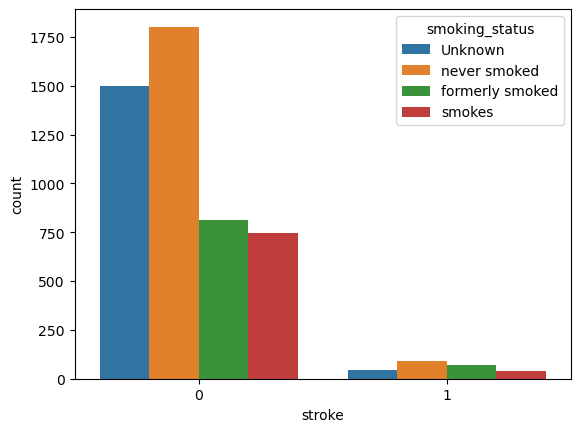

In [89]:
sns.countplot(x = df['stroke'],hue=df['smoking_status'])

<Axes: xlabel='age', ylabel='Count'>

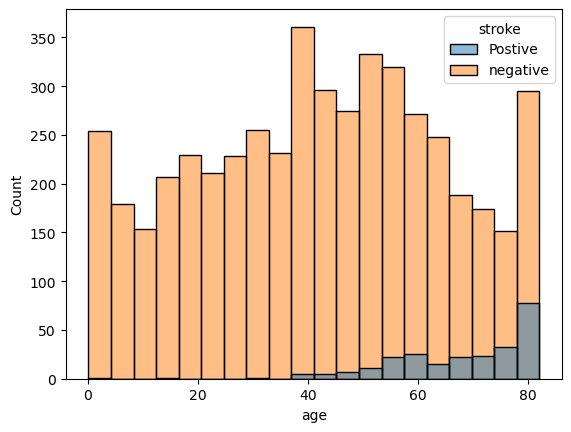

In [90]:
sns.histplot(x=df['age'],hue=df['stroke'].map({0: 'negative', 1: 'Postive'}))

In [91]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

<Axes: xlabel='stroke', ylabel='count'>

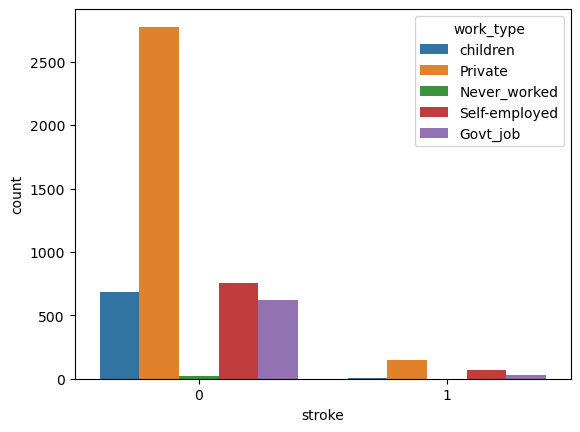

In [92]:
sns.countplot(data=df,x='stroke',hue='work_type')

<Axes: xlabel='stroke', ylabel='count'>

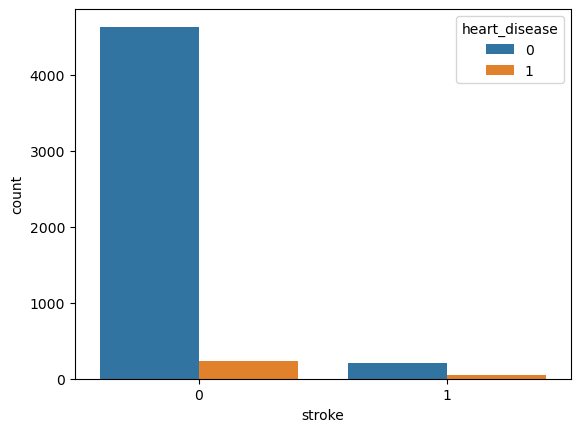

In [93]:
sns.countplot(data=df,x='stroke',hue='heart_disease')

In [94]:
df.drop('id',axis=1,inplace=True)

In [95]:
df.corr(numeric_only=True)

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
age,1.000000,0.276398,0.263796,0.238171,0.324296,0.245257
hypertension,0.276398,1.000000,0.108306,0.174474,0.158293,0.127904
heart_disease,0.263796,0.108306,1.000000,0.161857,0.036916,0.134914
avg_glucose_level,0.238171,0.174474,0.161857,1.000000,0.166876,0.131945
bmi,0.324296,0.158293,0.036916,0.166876,1.000000,0.036110
stroke,0.245257,0.127904,0.134914,0.131945,0.036110,1.000000


<Axes: >

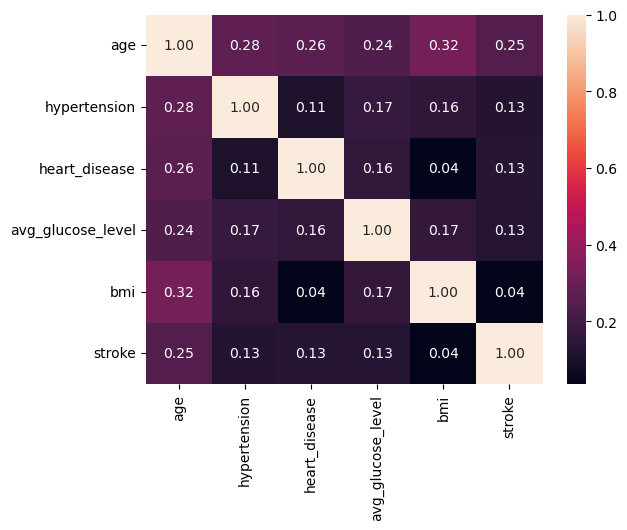

In [96]:
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt='0.2f')

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


In [98]:
df_new = df.select_dtypes('object')
df_new.nunique()

gender            3
ever_married      2
work_type         5
Residence_type    2
smoking_status    4
dtype: int64

In [99]:
from sklearn.preprocessing import LabelEncoder

In [100]:
lb = LabelEncoder()

In [101]:
df.select_dtypes('object').columns

Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='object')

In [102]:
for col in df.select_dtypes('object').columns[:-1]:
    df[col] = lb.fit_transform(df[col])
    print(lb.classes_)

['Female' 'Male' 'Other']
['No' 'Yes']
['Govt_job' 'Never_worked' 'Private' 'Self-employed' 'children']
['Rural' 'Urban']


In [103]:
from sklearn.preprocessing import OneHotEncoder

In [104]:
onehot = OneHotEncoder()

In [105]:
W= onehot.fit_transform(df[['smoking_status']]).toarray()

In [106]:
W

array([[0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 1., 0.],
       ...,
       [0., 0., 1., 0.],
       [0., 1., 0., 0.],
       [1., 0., 0., 0.]])

In [107]:
for ind , col in enumerate(onehot.categories_[0]):
    df[col]= W[:,ind]

In [108]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,Unknown,formerly smoked,never smoked,smokes
0,1,67.0,0,1,1,2,1,228.69,36.6,formerly smoked,1,0.0,1.0,0.0,0.0
1,0,61.0,0,0,1,3,0,202.21,28.1,never smoked,1,0.0,0.0,1.0,0.0
2,1,80.0,0,1,1,2,0,105.92,32.5,never smoked,1,0.0,0.0,1.0,0.0
3,0,49.0,0,0,1,2,1,171.23,34.4,smokes,1,0.0,0.0,0.0,1.0
4,0,79.0,1,0,1,3,0,174.12,24.0,never smoked,1,0.0,0.0,1.0,0.0


In [109]:
df.drop('smoking_status',axis=1,inplace=True)

In [110]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   stroke             5110 non-null   int64  
 10  Unknown            5110 non-null   float64
 11  formerly smoked    5110 non-null   float64
 12  never smoked       5110 non-null   float64
 13  smokes             5110 non-null   float64
dtypes: float64(7), int64(7)
memory usage: 559.0 KB


In [111]:
y=df['stroke']

In [112]:
X = df.drop('stroke',axis=1)

In [113]:
from sklearn.model_selection import train_test_split

In [114]:
X_train , X_test ,y_train,y_test=train_test_split(X,y,test_size=0.2,shuffle=True,
                                                  random_state=42,stratify=y)

In [115]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,\
f1_score,classification_report,confusion_matrix

In [145]:
models={
    "Logistics Regression":LogisticRegression(),
    
}

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       0.67      0.04      0.08        50

    accuracy                           0.95      1022
   macro avg       0.81      0.52      0.53      1022
weighted avg       0.94      0.95      0.93      1022



C:\Users\MG magic\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


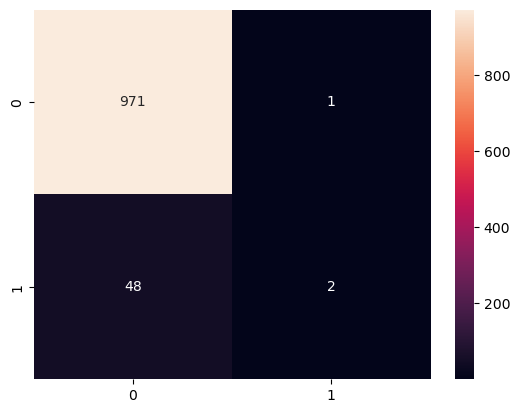

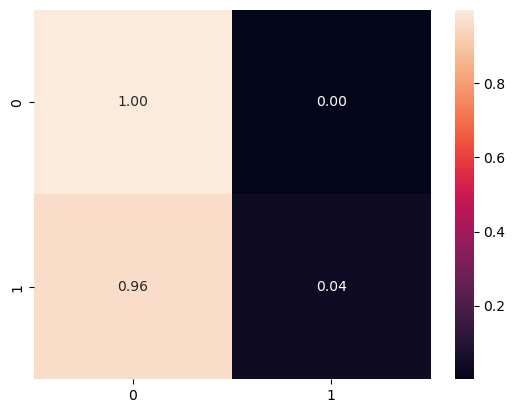

In [149]:
accuracys=[]
for model_name ,model in models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    print(classification_report(y_test,y_pred))
    accuracys.append([accuracy_score(y_test,y_pred),
                     precision_score(y_test,y_pred),
                     recall_score(y_test,y_pred),
                     f1_score(y_test,y_pred)]
                    )
    cm = confusion_matrix(y_test,y_pred)
    sns.heatmap(cm,annot=True,fmt='d')
    plt.show()
    cm = confusion_matrix(y_test,y_pred,normalize='true')
    sns.heatmap(cm,annot=True,fmt='0.2f')
    plt.show()

In [155]:
accuracys = pd.DataFrame(accuracys,index=models.keys(),columns=['Acc','Pre','Rec','F1'])

In [156]:
accuracys

,Acc,Pre,Rec,F1
Logistics Regression,0.952055,0.666667,0.04,0.075472


<Axes: >

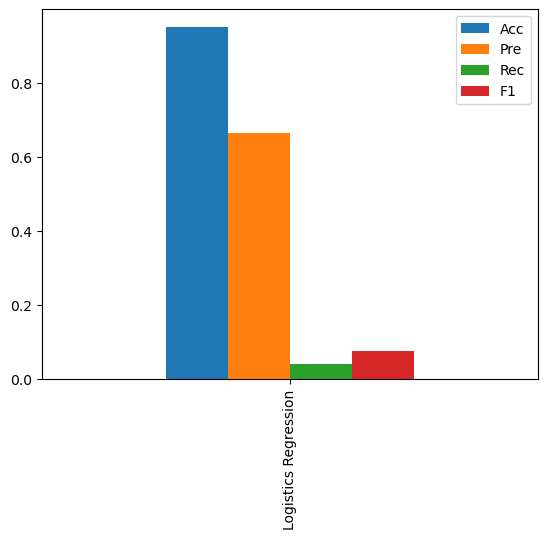

In [159]:
accuracys.plot(kind='bar')